### Predictive modeling of customer bookings

## Project Introduction (British Airways Booking Prediction)

This project aims to build a machine learning model that predicts whether a customer will make a flight booking with British Airways. By analyzing customer demographics, travel history, search behavior, and booking patterns, the system learns to identify key factors that drive booking decisions. This predictive model can help British Airways improve targeted marketing, optimize promotions, and enhance customer engagement strategies by focusing on customers most likely to convert.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from IPython.display import Image
from sklearn import tree
from sklearn import metrics
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from os import system
from sklearn.feature_extraction.text import CountVectorizer


In [6]:
df = pd.read_csv('customer_booking.csv', encoding="ISO-8859-1")

In [8]:
df.head()

,num_passengers,sales_channel,trip_type,purchase_lead,length_of_stay,flight_hour,flight_day,route,booking_origin,wants_extra_baggage,wants_preferred_seat,wants_in_flight_meals,flight_duration,booking_complete
0,2,Internet,RoundTrip,262,19,7,Sat,AKLDEL,New Zealand,1,0,0,5.52,0
1,1,Internet,RoundTrip,112,20,3,Sat,AKLDEL,New Zealand,0,0,0,5.52,0
2,2,Internet,RoundTrip,243,22,17,Wed,AKLDEL,India,1,1,0,5.52,0
3,1,Internet,RoundTrip,96,31,4,Sat,AKLDEL,New Zealand,0,0,1,5.52,0
4,2,Internet,RoundTrip,68,22,15,Wed,AKLDEL,India,1,0,1,5.52,0


In [10]:
df['booking_complete'].unique()

array([0, 1])

In [12]:
df['booking_complete'].value_counts()

booking_complete
0    42522
1     7478
Name: count, dtype: int64

# The Dataset is imbalanced 

In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   num_passengers         50000 non-null  int64  
 1   sales_channel          50000 non-null  object 
 2   trip_type              50000 non-null  object 
 3   purchase_lead          50000 non-null  int64  
 4   length_of_stay         50000 non-null  int64  
 5   flight_hour            50000 non-null  int64  
 6   flight_day             50000 non-null  object 
 7   route                  50000 non-null  object 
 8   booking_origin         50000 non-null  object 
 9   wants_extra_baggage    50000 non-null  int64  
 10  wants_preferred_seat   50000 non-null  int64  
 11  wants_in_flight_meals  50000 non-null  int64  
 12  flight_duration        50000 non-null  float64
 13  booking_complete       50000 non-null  int64  
dtypes: float64(1), int64(8), object(5)
memory usage: 5.3+ 

In [17]:
df.isnull().sum()

num_passengers           0
sales_channel            0
trip_type                0
purchase_lead            0
length_of_stay           0
flight_hour              0
flight_day               0
route                    0
booking_origin           0
wants_extra_baggage      0
wants_preferred_seat     0
wants_in_flight_meals    0
flight_duration          0
booking_complete         0
dtype: int64

In [23]:
df['flight_day'].unique()

array([6, 3, 4, 1, 7, 2, 5])

In [21]:
mapping = {
    "Mon": 1,
    "Tue": 2,
    "Wed": 3,
    "Thu": 4,
    "Fri": 5,
    "Sat": 6,
    "Sun": 7,
}

df["flight_day"] = df["flight_day"].map(mapping)

In [25]:
df.head()

,num_passengers,sales_channel,trip_type,purchase_lead,length_of_stay,flight_hour,flight_day,route,booking_origin,wants_extra_baggage,wants_preferred_seat,wants_in_flight_meals,flight_duration,booking_complete
0,2,Internet,RoundTrip,262,19,7,6,AKLDEL,New Zealand,1,0,0,5.52,0
1,1,Internet,RoundTrip,112,20,3,6,AKLDEL,New Zealand,0,0,0,5.52,0
2,2,Internet,RoundTrip,243,22,17,3,AKLDEL,India,1,1,0,5.52,0
3,1,Internet,RoundTrip,96,31,4,6,AKLDEL,New Zealand,0,0,1,5.52,0
4,2,Internet,RoundTrip,68,22,15,3,AKLDEL,India,1,0,1,5.52,0


In [35]:
df.dtypes

num_passengers             int64
sales_channel             object
trip_type                 object
purchase_lead              int64
length_of_stay             int64
flight_hour                int64
flight_day                 int64
route                     object
booking_origin            object
wants_extra_baggage        int64
wants_preferred_seat       int64
wants_in_flight_meals      int64
flight_duration          float64
booking_complete           int64
dtype: object

In [33]:
df['flight_day'] = df['flight_day'].astype(int) # changing flight day to int



In [37]:
df.shape

(50000, 14)

<Axes: xlabel='booking_complete'>

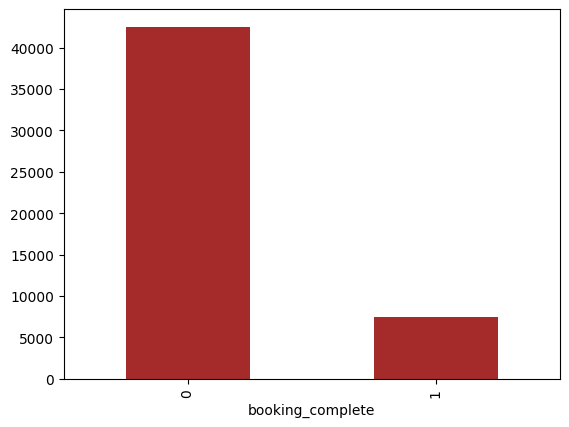

In [39]:
df['booking_complete'].value_counts().plot(kind='bar',color='brown')

<Axes: xlabel='sales_channel', ylabel='count'>

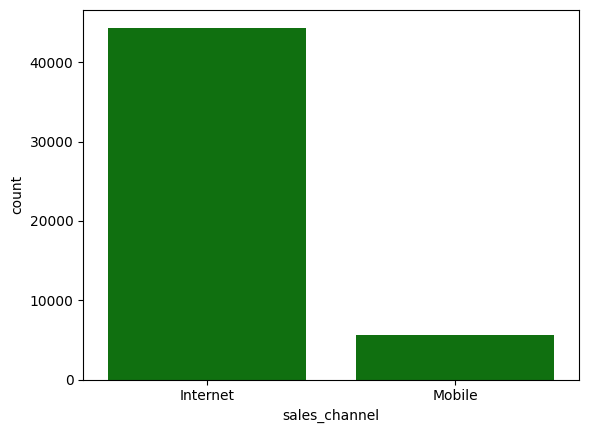

In [41]:
sns.countplot(data=df,x='sales_channel', color = 'green')

<Axes: xlabel='flight_day', ylabel='count'>

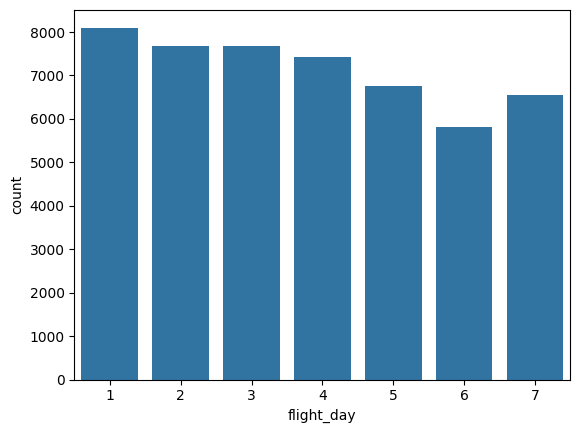

In [43]:
sns.countplot(data=df, x='flight_day')

# Feature Engineering

In [46]:
X = pd.get_dummies(df.drop('booking_complete',axis=1),drop_first=True,dtype = int)

In [48]:
X.head()

,num_passengers,purchase_lead,length_of_stay,flight_hour,flight_day,wants_extra_baggage,wants_preferred_seat,wants_in_flight_meals,flight_duration,sales_channel_Mobile,...,booking_origin_Timor-Leste,booking_origin_Tonga,booking_origin_Tunisia,booking_origin_Turkey,booking_origin_Ukraine,booking_origin_United Arab Emirates,booking_origin_United Kingdom,booking_origin_United States,booking_origin_Vanuatu,booking_origin_Vietnam
0,2,262,19,7,6,1,0,0,5.52,0,...,0,0,0,0,0,0,0,0,0,0
1,1,112,20,3,6,0,0,0,5.52,0,...,0,0,0,0,0,0,0,0,0,0
2,2,243,22,17,3,1,1,0,5.52,0,...,0,0,0,0,0,0,0,0,0,0
3,1,96,31,4,6,0,0,1,5.52,0,...,0,0,0,0,0,0,0,0,0,0
4,2,68,22,15,3,1,0,1,5.52,0,...,0,0,0,0,0,0,0,0,0,0


In [50]:
X.shape

(50000, 913)

In [52]:
y = df['booking_complete']

In [54]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
# Scale data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.30, random_state=101)

In [56]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier
    

In [58]:
# Define hyperparameter space
param_grid = {
    'n_estimators': [10, 50, 100, 200],
    'max_depth': [None, 5, 10],
    'min_samples_split': [2, 5, 10],
    'class_weight': ['balanced', None]
}

In [60]:
# Initialize random forest classifier
rfc = RandomForestClassifier(random_state=101)

# Initialize random search
rfs = RandomizedSearchCV(estimator=rfc, param_distributions=param_grid,
                                   cv=5, n_iter=10, random_state=101)


In [62]:

rfs.fit(X_train, y_train)


RandomizedSearchCV(cv=5, estimator=RandomForestClassifier(random_state=101),
                   param_distributions={'class_weight': ['balanced', None],
                                        'max_depth': [None, 5, 10],
                                        'min_samples_split': [2, 5, 10],
                                        'n_estimators': [10, 50, 100, 200]},
                   random_state=101)

In [64]:
best_model = rfs.best_estimator_

In [66]:
best_model

RandomForestClassifier(max_depth=5, random_state=101)

In [68]:
print('The Training data Score is:',best_model.score(X_train, y_train))
print('The Test data Score is:',best_model.score(X_test,y_test))

The Training data Score is: 0.8491142857142857
The Test data Score is: 0.8535333333333334


# Upsampling the data becuase the target data is imbalanced 

In [71]:
# separate minority and majority class
from sklearn.utils import resample

mj= df[df.booking_complete==0]
mn= df[df.booking_complete==1]


mj_upsampled = resample(mn,
                        replace=True,
                        n_samples=len(mj),
                        random_state = 42)



In [73]:
mj_upsampled = mj_upsampled.reset_index(drop=True)
mj_upsampled.head()

,num_passengers,sales_channel,trip_type,purchase_lead,length_of_stay,flight_hour,flight_day,route,booking_origin,wants_extra_baggage,wants_preferred_seat,wants_in_flight_meals,flight_duration,booking_complete
0,6,Internet,RoundTrip,119,6,11,6,OOLPEN,Malaysia,1,1,1,8.83,1
1,2,Internet,RoundTrip,60,196,8,1,COKPER,Australia,1,0,1,5.62,1
2,2,Internet,RoundTrip,109,5,3,1,KBVXIY,China,0,0,0,5.00,1
3,2,Internet,RoundTrip,46,5,13,1,ICNLGK,South Korea,0,0,0,6.62,1
4,1,Internet,RoundTrip,70,5,0,3,ICNJHB,Malaysia,1,1,1,6.62,1


In [75]:
frame = [df,mj_upsampled]
df = pd.concat(frame, axis = 0)

In [77]:
df.head()

,num_passengers,sales_channel,trip_type,purchase_lead,length_of_stay,flight_hour,flight_day,route,booking_origin,wants_extra_baggage,wants_preferred_seat,wants_in_flight_meals,flight_duration,booking_complete
0,2,Internet,RoundTrip,262,19,7,6,AKLDEL,New Zealand,1,0,0,5.52,0
1,1,Internet,RoundTrip,112,20,3,6,AKLDEL,New Zealand,0,0,0,5.52,0
2,2,Internet,RoundTrip,243,22,17,3,AKLDEL,India,1,1,0,5.52,0
3,1,Internet,RoundTrip,96,31,4,6,AKLDEL,New Zealand,0,0,1,5.52,0
4,2,Internet,RoundTrip,68,22,15,3,AKLDEL,India,1,0,1,5.52,0


In [79]:
df['booking_complete'].value_counts()

booking_complete
1    50000
0    42522
Name: count, dtype: int64

<Axes: xlabel='booking_complete'>

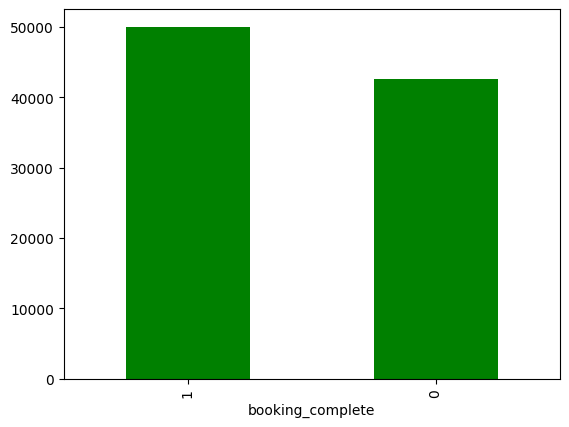

In [81]:
df['booking_complete'].value_counts().plot(kind='bar',color='green')

In [83]:
X = pd.get_dummies(df.drop('booking_complete',axis=1),drop_first=True, dtype= int)

In [85]:
y = df['booking_complete']
y = y.values.reshape(-1,1)

In [87]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler


# Scale data

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


# Split data into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier


# Define hyperparameter space

param_grid = {
    'n_estimators': [10, 50, 100, 200],
    'max_depth': [None, 5, 10],
    'min_samples_split': [2, 5, 10],
    'class_weight': ['balanced', None]
}

# Initialize random forest classifier
rfc = RandomForestClassifier(random_state=42)

# Initialize random search
rfs = RandomizedSearchCV(estimator=rfc, param_distributions=param_grid,
                         cv=5, n_iter=10, random_state=42)

rfs.fit(X_train, y_train)
rfs


RandomizedSearchCV(cv=5, estimator=RandomForestClassifier(random_state=42),
                   param_distributions={'class_weight': ['balanced', None],
                                        'max_depth': [None, 5, 10],
                                        'min_samples_split': [2, 5, 10],
                                        'n_estimators': [10, 50, 100, 200]},
                   random_state=42)

The Training data Score is: 0.9990948025453612
The Test data Score is: 0.9596865711969738


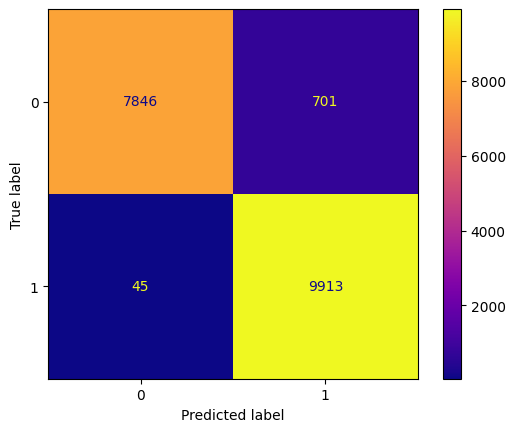

In [89]:
best_model2 = rfs.best_estimator_

print('The Training data Score is:',best_model2.score(X_train, y_train))
print('The Test data Score is:',best_model2.score(X_test,y_test))

from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_estimator(best_model2,X_test,y_test,cmap='plasma')

In [91]:
# Get feature importance values
feature_importances = best_model2.feature_importances_

# Get feature names
feature_names = X.columns

# Create a DataFrame with feature names and importance values
feature_importance_df = pd.DataFrame({
    "Feature Name": feature_names,
    "Importance": feature_importances
})

In [93]:
# Print the DataFrame
feature_importance_df.head()

,Feature Name,Importance
0,num_passengers,0.041032
1,purchase_lead,0.137822
2,length_of_stay,0.109894
3,flight_hour,0.106725
4,flight_day,0.074734


In [95]:
# Sort the DataFrame by importance in descending order
feature_importance_df = feature_importance_df.sort_values(by="Importance", ascending=False)


In [97]:
feature_importance_df.head()

,Feature Name,Importance
1,purchase_lead,0.137822
2,length_of_stay,0.109894
3,flight_hour,0.106725
4,flight_day,0.074734
8,flight_duration,0.042561


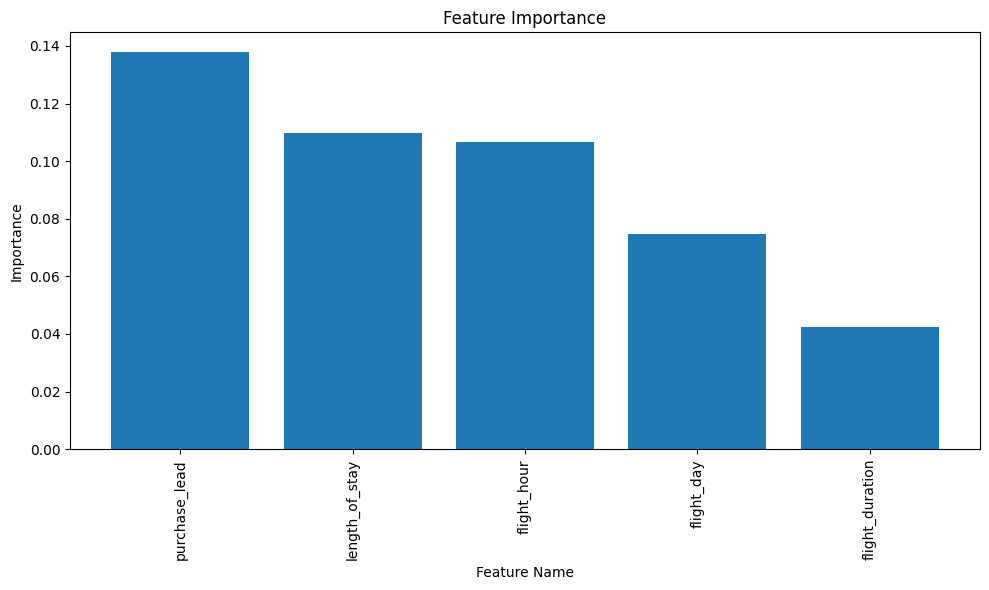

In [99]:
# Plot a multiple color bar
plt.figure(figsize=(10, 6))
plt.bar(feature_importance_df["Feature Name"].head(), feature_importance_df["Importance"].head(), color=plt.cm.tab20(np.linspace(0, 1, len(feature_importance_df))))
plt.xlabel("Feature Name")
plt.ylabel("Importance")
plt.title("Feature Importance")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [101]:
from sklearn.model_selection import cross_val_score

In [103]:
# Cross-validation accuracy
accuracy_scores = cross_val_score(best_model2, X, y, cv=5, scoring='accuracy')
print("Cross-validation accuracy:", accuracy_scores.mean())

Cross-validation accuracy: 0.8263862695643306


In [104]:
# Cross-validation precision
precision_scores = cross_val_score(best_model2, X, y, cv=5, scoring='precision')
print("Cross-validation precision:", precision_scores.mean())

Cross-validation precision: 0.7610082718415305


In [105]:
# Cross-validation recall
recall_scores = cross_val_score(best_model2, X, y, cv=5, scoring='recall')
print("Cross-validation recall:", recall_scores.mean())

Cross-validation recall: 0.9982200000000001


In [106]:
# Cross-validation F1-score
f1_scores = cross_val_score(best_model2, X, y, cv=5, scoring='f1')
print("Cross-validation F1-score:", f1_scores.mean())

Cross-validation F1-score: 0.862652113981043


In [107]:
# Cross-validation ROC-AUC
roc_auc_scores = cross_val_score(best_model2, X, y, cv=5, scoring='roc_auc')
print("Cross-validation ROC-AUC:", roc_auc_scores.mean())

Cross-validation ROC-AUC: 0.967886750503688


In [113]:
# Cross-validation metrics
metrics = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']

In [115]:
# Initialize lists to store the results
mean_scores = []

In [117]:
# Perform cross-validation for each metric
for metric in metrics:
    scores = cross_val_score(best_model2, X, y, cv=5, scoring=metric)
    mean_scores.append(scores.mean())


In [118]:
# Create a DataFrame with the results
cv_results_df = pd.DataFrame({
    "Metric": metrics,
    "Mean Score": mean_scores
})


In [119]:
cv_results_df

,Metric,Mean Score
0,accuracy,0.826386
1,precision,0.761008
2,recall,0.998220
3,f1,0.862652
4,roc_auc,0.967887


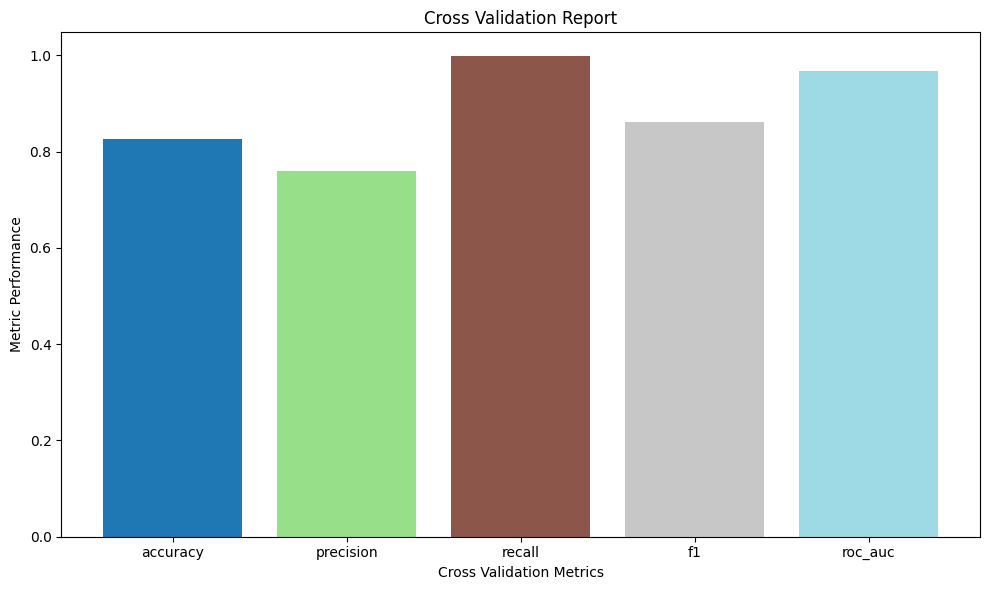

In [120]:
# Plot a multiple color bar
plt.figure(figsize=(10, 6))
plt.bar(cv_results_df["Metric"], cv_results_df["Mean Score"], color=plt.cm.tab20(np.linspace(0, 1, len(cv_results_df))))
plt.xlabel("Cross Validation Metrics")
plt.ylabel("Metric Performance")
plt.title("Cross Validation Report")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()